# v2_forces — Forces d'attaque et de défense, valeur des joueurs récents

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie modèle : Moussa

## Pourquoi ce notebook ?
Le modèle de scores (`MODEL_POISSON.ipynb`) résume le niveau d'une équipe par **un seul nombre**, l'Elo. Deux informations lui manquent :

1. **Le style de l'équipe.** Deux clubs de même Elo peuvent être très différents : l'un marque beaucoup et encaisse beaucoup, l'autre marque peu et n'encaisse presque rien. On estime donc une **force d'attaque** et une **force de défense** par club, sur **tous les matchs de `games.csv`** (championnats, coupes, Europe : environ 18 000 matchs par calcul), et plus seulement sur les 1 871 matchs de C1.
2. **L'état de l'effectif au moment du match.** Un joueur clé blessé depuis trois semaines ne joue plus. On mesure donc la **valeur des 11 joueurs qui ont le plus joué lors des 5 derniers matchs**.

## La règle d'or : rien du futur
| Variable | Ce qu'on utilise pour un match joué le jour J |
|---|---|
| Forces d'attaque et de défense | uniquement les matchs joués **avant le 1er du mois** de J, sur les 3 années précédentes |
| Valeur des joueurs récents | les 5 derniers matchs du club **strictement avant J**, et la dernière valeur Transfermarkt connue **avant J** |

## Ce que produit le notebook
- `output/forces_par_match.csv` : une ligne par match de C1 (1 871), les deux variables pour les deux équipes ;
- `output/forces_participants_2026.csv` : les 36 clubs de 2026-2027, à la veille de la phase de ligue (forces au 1er septembre 2026, joueurs récents avant le 8 septembre 2026).

## Plan
1. Les données
2. Les forces d'attaque et de défense
3. La valeur des joueurs récents
4. Contrôles et lien avec les résultats
5. Export
6. Conclusion

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.linear_model import PoissonRegressor

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, GRIS, ENCRE = '#2a78d6', '#eb6834', '#b5b3ad', '#52514e'

# Réglages choisis en validation glissante dans MODEL_POISSON (section 10) : 18 combinaisons comparées
FENETRE_JOURS = 1095        # mémoire : les 3 dernières années
DEMI_VIE_JOURS = 480        # un match perd la moitié de son poids en 480 jours
ALPHA = 1e-4                # très légère pénalité, pour stabiliser les clubs qui ont peu de matchs
NB_MATCHS, NB_JOUEURS = 5, 11
COUPURE_2026, DEBUT_2026 = pd.Timestamp('2026-09-01'), pd.Timestamp('2026-09-08')

games = pd.read_csv('../data/games.csv', parse_dates=['date'],
                    usecols=['game_id', 'competition_type', 'date', 'home_club_id', 'away_club_id',
                             'home_club_goals', 'away_club_goals'])
# On garde les matchs officiels de clubs : ni équipes nationales, ni compétitions de type inconnu
inconnus = games['competition_type'].isna()
games = games[(games['competition_type'] != 'national_team_competition') & ~inconnus].dropna(subset=['home_club_goals', 'away_club_goals'])

# Les scores qui incluent les tirs au but : on les ramène à un nul (on ne connaît pas le score après 120 minutes)
evenements = pd.read_csv('../data/game_events.csv', usecols=['game_id', 'type'])
tirs_au_but = games['game_id'].isin(evenements.loc[evenements['type'] == 'Shootout', 'game_id'])
faux = tirs_au_but & (games['home_club_goals'] != games['away_club_goals'])
plus_petit = np.minimum(games.loc[faux, 'home_club_goals'], games.loc[faux, 'away_club_goals'])
games.loc[faux, 'home_club_goals'], games.loc[faux, 'away_club_goals'] = plus_petit, plus_petit
# Scores aberrants (plus de 15 buts pour une équipe : erreurs de saisie ou matchs sans enjeu) : retirés
aberrants = (games['home_club_goals'] > 15) | (games['away_club_goals'] > 15)
games = games[~aberrants]

c1 = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig', parse_dates=['date'],
                 usecols=['game_id', 'date', 'season', 'home_club_id', 'away_club_id', 'home_club_name', 'away_club_name',
                          'ecart_elo_complet', 'resultat'])
participants = pd.read_csv('../output/elo_participants_2026.csv')

print(f"games.csv : {len(games):,} matchs de clubs, du {games['date'].min():%d/%m/%Y} au {games['date'].max():%d/%m/%Y}")
print(f"Matchs de compétitions inconnues retirés : {inconnus.sum():,} | scores corrigés des tirs au but : {faux.sum():,} | scores aberrants retirés : {aberrants.sum()}")
print(f"Matchs de C1 : {len(c1):,} | participants 2026-2027 : {len(participants)}")

games.csv : 86,998 matchs de clubs, du 03/07/2012 au 06/07/2026
Matchs de compétitions inconnues retirés : 1,214 | scores corrigés des tirs au but : 1,131 | scores aberrants retirés : 4
Matchs de C1 : 1,871 | participants 2026-2027 : 36


## 1. Les données

`games.csv` contient les matchs de clubs de la plupart des grands championnats européens, de leurs coupes et des compétitions européennes. On retire les matchs d'équipes nationales, et on corrige les scores qui incluent les tirs au but : un match décidé aux tirs au but compte comme un nul.

**Une limite à garder en tête :** `games.csv` commence en juillet 2012 et s'arrête début juillet 2026. Pour les premières saisons de C1, la mémoire de 3 ans n'est pas encore remplie ; pour 2026-2027, les matchs les plus récents sont ceux de la fin de la saison 2025-2026.

## 2. Les forces d'attaque et de défense

**Le modèle**, appris sur les matchs passés, avec une ligne par équipe et par match :

$$\log(\text{buts marqués}) = \mu + \text{attaque}(\text{équipe}) + \text{défense}(\text{adversaire}) + \text{domicile}$$

- **attaque** : plus elle est élevée, plus l'équipe marque, quel que soit l'adversaire ;
- **défense** : plus elle est élevée, plus l'équipe **laisse marquer** ses adversaires (donc une bonne défense a une valeur basse) ;
- les matchs récents comptent plus : un match perd la moitié de son poids en 480 jours, et on s'arrête à 3 ans.

**Pour chaque mois**, on refait le calcul avec les seuls matchs joués **avant le 1er du mois**, puis on l'applique aux matchs de C1 de ce mois. Les forces ne voient donc jamais le match qu'elles servent à prédire.

**La variable donnée au modèle de scores**, pour chaque équipe d'un match : `force_ad = attaque(équipe) + défense(adversaire)`. C'est le logarithme des buts que l'équipe « devrait » marquer contre cet adversaire, d'après tous ses matchs récents.

In [2]:
def forces_au(coupure):
    # Forces d'attaque et de défense de tous les clubs, apprises sur les matchs joués avant `coupure`
    passe = games[(games['date'] < coupure) & (games['date'] >= coupure - pd.Timedelta(days=FENETRE_JOURS))]
    clubs = pd.Index(np.unique(np.r_[passe['home_club_id'], passe['away_club_id']]))
    n, k = len(passe), len(clubs)
    i_dom, i_ext = clubs.get_indexer(passe['home_club_id']), clubs.get_indexer(passe['away_club_id'])
    lignes = np.arange(2 * n)
    attaque = sp.csr_matrix((np.ones(2 * n), (lignes, np.r_[i_dom, i_ext])), shape=(2 * n, k))
    defense = sp.csr_matrix((np.ones(2 * n), (lignes, np.r_[i_ext, i_dom])), shape=(2 * n, k))
    domicile = sp.csr_matrix(np.r_[np.ones(n), np.zeros(n)][:, None])
    X = sp.hstack([attaque, defense, domicile]).tocsr()
    y = np.r_[passe['home_club_goals'], passe['away_club_goals']]
    age = (coupure - passe['date']).dt.days.to_numpy()
    poids = np.tile(0.5 ** (age / DEMI_VIE_JOURS), 2)
    reg = PoissonRegressor(alpha=ALPHA, max_iter=300).fit(X, y, sample_weight=poids)
    matchs_par_club = pd.Series(np.r_[i_dom, i_ext]).value_counts().reindex(range(k), fill_value=0).to_numpy()
    return pd.DataFrame({'attaque': reg.coef_[:k], 'defense': reg.coef_[k:2 * k], 'nb_matchs': matchs_par_club},
                        index=clubs), passe['date'].max(), n

c1['coupure'] = c1['date'].dt.to_period('M').dt.to_timestamp()
lignes_forces = []
for coupure, matchs in c1.groupby('coupure'):
    forces, dernier_match, n_matchs = forces_au(coupure)
    assert dernier_match < coupure <= matchs['date'].min(), "Un match du mois de prédiction a été utilisé"
    for _, m in matchs.iterrows():
        f_dom = forces.loc[m['home_club_id']] if m['home_club_id'] in forces.index else pd.Series(np.nan, index=forces.columns)
        f_ext = forces.loc[m['away_club_id']] if m['away_club_id'] in forces.index else pd.Series(np.nan, index=forces.columns)
        lignes_forces.append({'game_id': m['game_id'], 'attaque_dom': f_dom['attaque'], 'defense_dom': f_dom['defense'],
                              'attaque_ext': f_ext['attaque'], 'defense_ext': f_ext['defense'],
                              'nb_matchs_forces_dom': f_dom['nb_matchs'], 'nb_matchs_forces_ext': f_ext['nb_matchs'],
                              'matchs_dans_le_calcul': n_matchs})
forces_c1 = pd.DataFrame(lignes_forces)
forces_c1['force_ad_dom'] = forces_c1['attaque_dom'] + forces_c1['defense_ext']
forces_c1['force_ad_ext'] = forces_c1['attaque_ext'] + forces_c1['defense_dom']

forces_2026, dernier_2026, n_2026 = forces_au(COUPURE_2026)
print(f"{c1['coupure'].nunique()} calculs mensuels | {len(forces_c1):,} matchs de C1 | "
      f"matchs de C1 sans force pour une équipe : {forces_c1['force_ad_dom'].isna().sum()}")
print(f"Calcul 2026-2027 : {n_2026:,} matchs, le dernier le {dernier_2026:%d/%m/%Y}")

116 calculs mensuels | 1,871 matchs de C1 | matchs de C1 sans force pour une équipe : 0
Calcul 2026-2027 : 23,794 matchs, le dernier le 06/07/2026


Les 10 meilleures attaques et les 10 meilleures défenses des participants (× la moyenne des clubs de games.csv) :


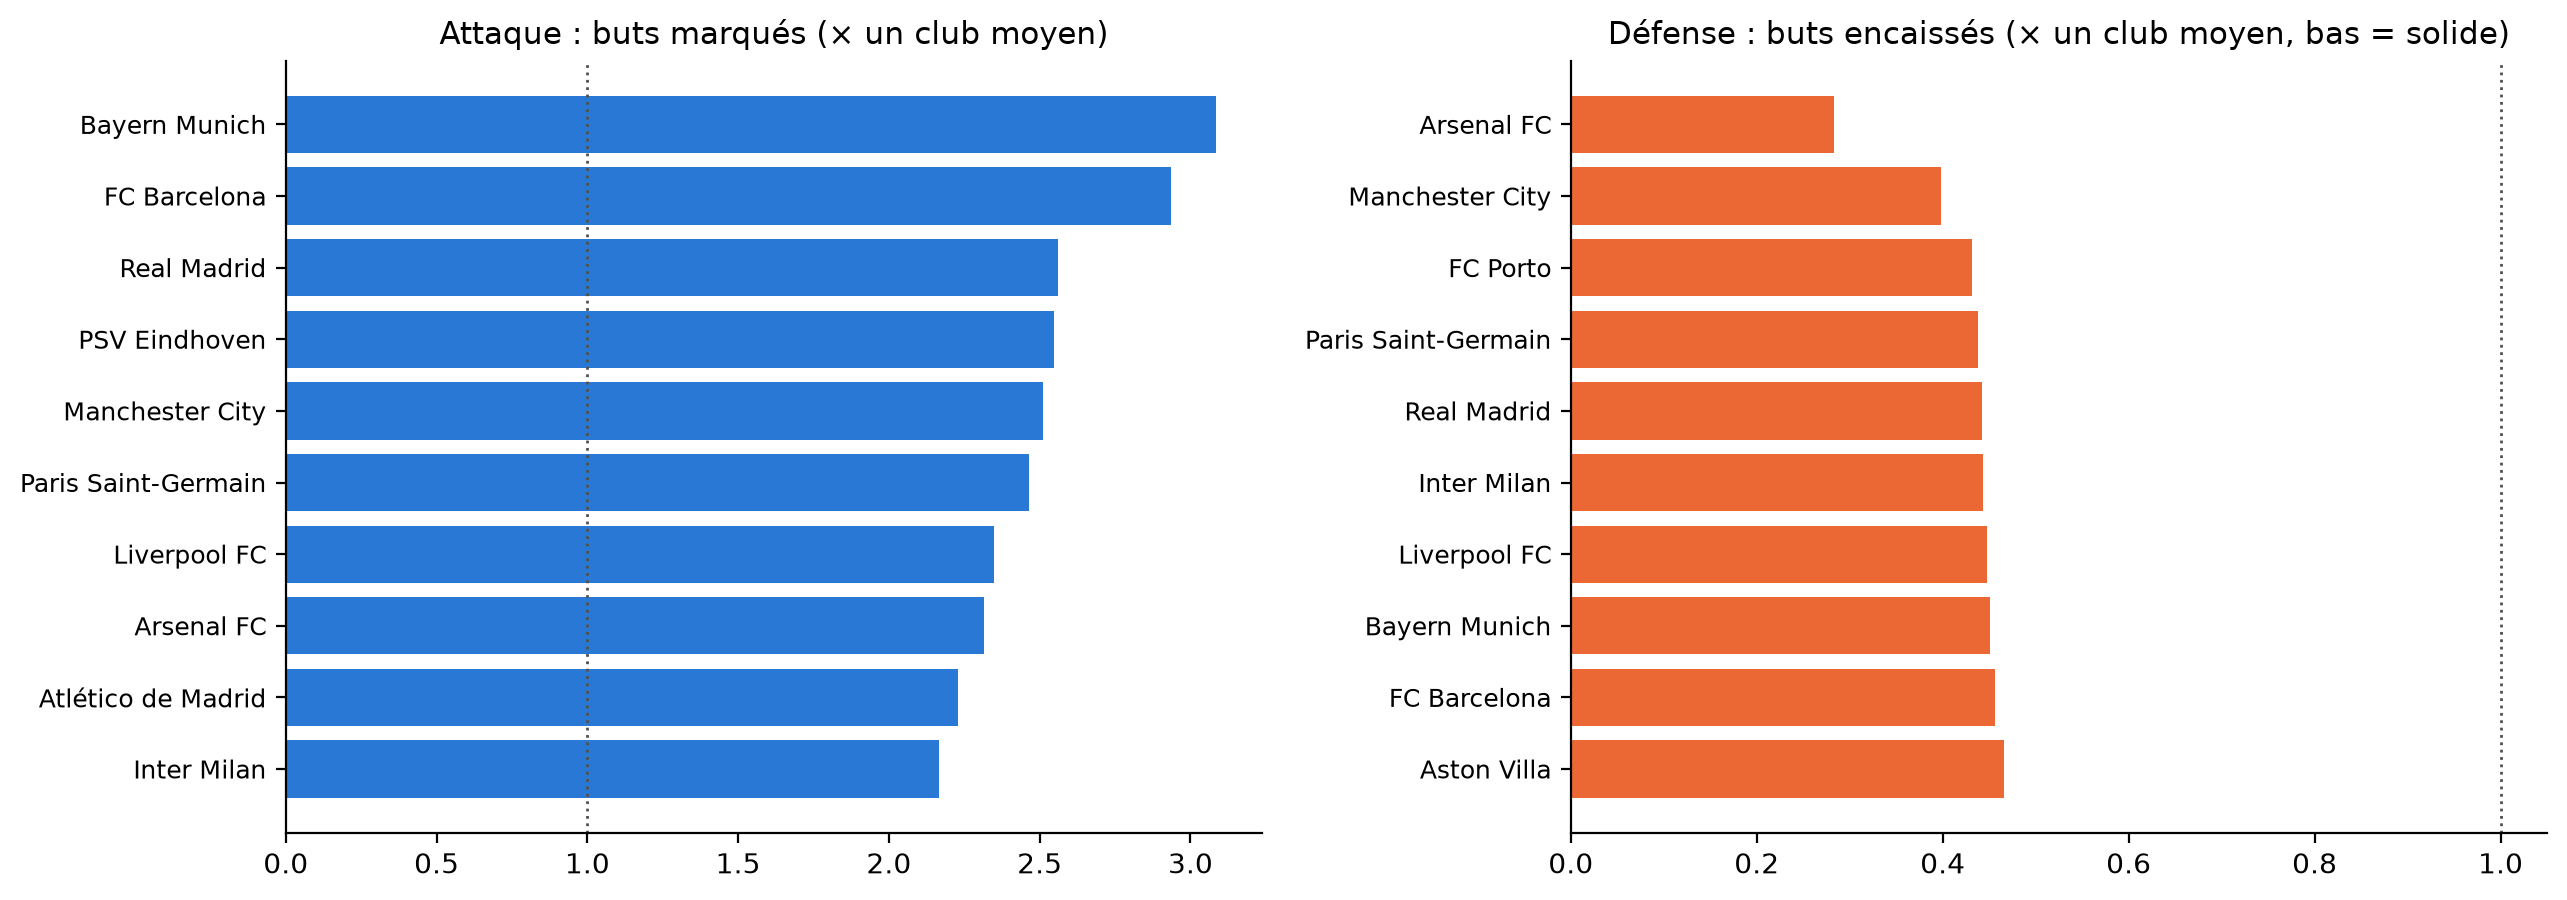

,club,elo_complet,nb_matchs,buts_marques_vs_moyen,buts_encaisses_vs_moyen
0,Arsenal FC,2025,155,2.32,0.28
1,Manchester City,1989,159,2.51,0.40
2,Bayern Munich,1972,151,3.08,0.45
3,FC Barcelona,1970,167,2.93,0.46
4,Inter Milan,1943,159,2.17,0.44
5,Real Madrid,1932,169,2.56,0.44
6,Paris Saint-Germain,1920,148,2.47,0.44
7,Liverpool FC,1895,154,2.35,0.45
8,Manchester United,1889,143,2.07,0.54
9,Aston Villa,1860,159,1.91,0.47


In [3]:
# Les forces des 36 participants de 2026-2027, au 1er septembre 2026
part = participants[['club', 'club_id', 'elo_complet']].merge(forces_2026, left_on='club_id', right_index=True, how='left')
part['buts_marques_vs_moyen'] = np.exp(part['attaque'] - forces_2026['attaque'].median())
part['buts_encaisses_vs_moyen'] = np.exp(part['defense'] - forces_2026['defense'].median())
print("Les 10 meilleures attaques et les 10 meilleures défenses des participants (× la moyenne des clubs de games.csv) :")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col, couleur, titre in [(ax1, 'buts_marques_vs_moyen', BLEU, 'Attaque : buts marqués (× un club moyen)'),
                                 (ax2, 'buts_encaisses_vs_moyen', ORANGE, 'Défense : buts encaissés (× un club moyen, bas = solide)')]:
    t = part.sort_values(col, ascending=(col == 'buts_encaisses_vs_moyen')).head(10).iloc[::-1]
    ax.barh(t['club'], t[col], color=couleur)
    ax.axvline(1, color=ENCRE, linestyle=':', linewidth=1)
    ax.set_title(titre, fontsize=11)
    ax.tick_params(axis='y', labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
part[['club', 'elo_complet', 'nb_matchs', 'buts_marques_vs_moyen', 'buts_encaisses_vs_moyen']] \
    .sort_values('elo_complet', ascending=False).round(2).reset_index(drop=True)

**Lecture :**
- **Les forces confirment l'Elo, avec des nuances qu'il ne voit pas.** Les grands clubs ont à la fois une forte attaque et une forte défense.
- **Bayern et Barcelone ont les meilleures attaques** : ils marquent environ **3 fois plus** qu'un club moyen de `games.csv` (× 3,08 et × 2,93), devant Real Madrid (× 2,56), Manchester City (× 2,51) et le PSG (× 2,47).
- **Arsenal a de loin la meilleure défense** : il n'encaisse que **0,28 fois** ce qu'encaisse un club moyen, devant Manchester City (0,40). C'est ce qui en fait le favori, plus que son attaque (× 2,32).
- **Deux clubs de même Elo peuvent avoir des profils opposés.** Le PSV (Elo 1 799) a une attaque presque au niveau des meilleurs (× 2,55), mais une défense fragile (0,60) : ses matchs devraient avoir plus de buts. Lille (Elo 1 789) attaque beaucoup moins (× 1,47), avec une défense solide (0,48). L'Elo seul les met au même niveau.
- **Les petits clubs ont des forces moins sûres** : Sabah n'a que 10 matchs dans la fenêtre de 3 ans, Slovan Bratislava 36, Viking 44 (leur championnat n'est pas dans `games.csv` : seuls leurs matchs européens comptent).

## 3. La valeur des joueurs récents

**La définition**, pour un club et un match joué le jour J :
1. on prend ses **5 derniers matchs officiels** joués **strictement avant J** (`appearances.csv`) ;
2. on garde les **11 joueurs qui y ont joué le plus de minutes** : son équipe « du moment » ;
3. on additionne leur **dernière valeur Transfermarkt connue avant J** (`player_valuations.csv`).

**La variable donnée au modèle :** `ecart_valeur_recente` = log(valeur du club qui reçoit) − log(valeur de l'autre). Si un joueur clé est blessé depuis plusieurs matchs, il sort des 11, et la valeur baisse.

**Ce n'est pas la composition du match**, inconnue à l'avance : seulement les matchs déjà joués. La variable est donc connue à n'importe quelle date, y compris le 8 septembre 2026 pour prévoir toute la saison.

In [4]:
apparitions = pd.read_csv('../data/appearances.csv', parse_dates=['date'],
                          usecols=['game_id', 'player_id', 'player_club_id', 'date', 'minutes_played'])
apparitions = apparitions[apparitions['minutes_played'] > 0]
valeurs = pd.read_csv('../data/player_valuations.csv', parse_dates=['date'],
                      usecols=['player_id', 'date', 'market_value_in_eur']).sort_values('date')
par_club = {club: d.sort_values('date') for club, d in apparitions.groupby('player_club_id')}
matchs_du_club = {club: d.drop_duplicates('game_id')[['game_id', 'date']].reset_index(drop=True) for club, d in par_club.items()}

def noyau_recent(club, jour):
    # Les 11 joueurs les plus utilisés lors des 5 derniers matchs du club, strictement avant `jour`
    jm = matchs_du_club.get(club)
    if jm is None:
        return pd.Index([]), pd.NaT
    avant = jm[jm['date'] < jour].tail(NB_MATCHS)
    if avant.empty:
        return pd.Index([]), pd.NaT
    joueurs = par_club[club][par_club[club]['game_id'].isin(avant['game_id'])]
    return joueurs.groupby('player_id')['minutes_played'].sum().nlargest(NB_JOUEURS).index, avant['date'].max()

demandes, derniers = [], {}
cas = [(m['game_id'], cote, club, m['date']) for _, m in c1.iterrows()
       for cote, club in [('dom', m['home_club_id']), ('ext', m['away_club_id'])]]
cas += [(f"2026_{club}", 'club', club, DEBUT_2026) for club in participants['club_id']]
for cle, cote, club, jour in cas:
    joueurs, dernier = noyau_recent(club, jour)
    derniers[(cle, cote)] = dernier
    assert pd.isna(dernier) or dernier < jour, "Un match du jour même ou d'après a été utilisé"
    demandes += [{'cle': cle, 'cote': cote, 'player_id': p, 'date': jour} for p in joueurs]

demandes = pd.merge_asof(pd.DataFrame(demandes).sort_values('date'), valeurs, on='date', by='player_id',
                         allow_exact_matches=False)                    # valeur connue strictement avant le jour du match
valeur = demandes.groupby(['cle', 'cote'])['market_value_in_eur'].sum(min_count=1)

forces_c1['valeur_recente_dom_eur'] = [valeur.get((g_, 'dom'), np.nan) for g_ in forces_c1['game_id']]
forces_c1['valeur_recente_ext_eur'] = [valeur.get((g_, 'ext'), np.nan) for g_ in forces_c1['game_id']]
forces_c1['ecart_valeur_recente'] = np.log(forces_c1['valeur_recente_dom_eur']) - np.log(forces_c1['valeur_recente_ext_eur'])
part['valeur_recente_eur'] = [valeur.get((f"2026_{c}", 'club'), np.nan) for c in part['club_id']]
part['dernier_match_utilise'] = [derniers[(f"2026_{c}", 'club')] for c in part['club_id']]
print(f"Valeur des joueurs récents calculée pour {forces_c1['ecart_valeur_recente'].notna().mean():.1%} des matchs de C1")

Valeur des joueurs récents calculée pour 100.0% des matchs de C1


## 4. Contrôles et lien avec les résultats

On vérifie trois choses :
1. **aucune fuite** : les `assert` ci-dessus garantissent que tout ce qui est utilisé est antérieur au match ;
2. **le lien avec le résultat** : les nouvelles variables doivent prédire le résultat, sinon elles sont inutiles ;
3. **le lien avec l'Elo** : si elles suivaient parfaitement l'Elo, elles n'apporteraient rien de nouveau.

In [5]:
etude = c1[['game_id', 'season', 'ecart_elo_complet', 'resultat']].merge(forces_c1, on='game_id')
etude['score_domicile'] = etude['resultat'].map({'Victoire domicile': 1.0, 'Nul': 0.5, 'Victoire extérieur': 0.0})
etude['ecart_force_ad'] = etude['force_ad_dom'] - etude['force_ad_ext']
liens = pd.DataFrame({
    'corrélation avec le résultat': [etude[v].corr(etude['score_domicile'], method='spearman') for v in
                                     ['ecart_elo_complet', 'ecart_force_ad', 'ecart_valeur_recente']],
    "corrélation avec l'écart d'Elo": [1.0, etude['ecart_force_ad'].corr(etude['ecart_elo_complet'], method='spearman'),
                                       etude['ecart_valeur_recente'].corr(etude['ecart_elo_complet'], method='spearman')],
}, index=["écart d'Elo", "écart de forces d'attaque/défense", 'écart de valeur des joueurs récents'])

# Les petits clubs dont les informations sont anciennes ou maigres
fragiles = part[(part['nb_matchs'] < 60) | (part['dernier_match_utilise'] < pd.Timestamp('2026-05-01'))]
print("Participants 2026-2027 aux informations fragiles (moins de 60 matchs en 3 ans, ou derniers matchs anciens) :")
print(fragiles[['club', 'nb_matchs', 'dernier_match_utilise']].to_string(index=False))
liens.round(3)

Participants 2026-2027 aux informations fragiles (moins de 60 matchs en 3 ans, ou derniers matchs anciens) :
                              club  nb_matchs dernier_match_utilise
Athlitiki Enosi Konstantinoupoleos        116            2026-03-22
         Fotballklubben Bodø/Glimt         85            2026-03-17
               Viking Fotballklubb         44            2025-08-13
                          Sabah FK         10            2025-08-14
                  SK Slavia Prague         88            2026-01-28
                              LASK         74            2024-08-29
                 Slovan Bratislava         36            2025-08-28


,corrélation avec le résultat,corrélation avec l'écart d'Elo
écart d'Elo,0.476,1.000
écart de forces d'attaque/défense,0.459,0.885
écart de valeur des joueurs récents,0.456,0.877


**Lecture :**
- **Aucune fuite** : tous les contrôles passent (les forces sont apprises avant le mois du match, les joueurs récents viennent de matchs antérieurs).
- **Les deux nouvelles variables sont presque aussi liées au résultat que l'Elo** : corrélation de 0,46 pour les deux, contre 0,48 pour l'Elo.
- **Mais elles ne sont pas une copie de l'Elo** : leur corrélation avec lui est de 0,88. Une partie de l'information est donc nouvelle. C'est cette partie que le modèle de scores va pouvoir utiliser (`MODEL_POISSON`, section 10).
- **Sept participants ont des informations fragiles**, soit peu de matchs, soit des derniers matchs anciens : AEK Athènes, Bodø/Glimt et Slavia Prague (derniers matchs connus entre janvier et mars 2026), Viking, Sabah et Slovan Bratislava (août 2025), et LASK (août 2024). Pour eux, la « valeur des joueurs récents » décrit un effectif ancien. C'était déjà le cas pour les petits clubs dans les données d'apprentissage : le modèle a appris avec ce bruit.

## 5. Export

In [6]:
colonnes = ['game_id', 'attaque_dom', 'defense_dom', 'attaque_ext', 'defense_ext', 'force_ad_dom', 'force_ad_ext',
            'nb_matchs_forces_dom', 'nb_matchs_forces_ext', 'valeur_recente_dom_eur', 'valeur_recente_ext_eur', 'ecart_valeur_recente']
sortie = forces_c1[colonnes]
assert len(sortie) == len(c1) and sortie['game_id'].is_unique and set(sortie['game_id']) == set(c1['game_id'])
sortie.to_csv('../output/forces_par_match.csv', index=False, encoding='utf-8-sig')

sortie_2026 = part[['club_id', 'club', 'attaque', 'defense', 'nb_matchs', 'valeur_recente_eur', 'dernier_match_utilise']]
assert len(sortie_2026) == 36 and sortie_2026['club_id'].is_unique
sortie_2026.to_csv('../output/forces_participants_2026.csv', index=False, encoding='utf-8-sig')
print(f"output/forces_par_match.csv : {len(sortie):,} lignes | output/forces_participants_2026.csv : {len(sortie_2026)} clubs")
print("Valeurs manquantes (2026) :", sortie_2026[['attaque', 'valeur_recente_eur']].isna().sum().to_dict())

output/forces_par_match.csv : 1,871 lignes | output/forces_participants_2026.csv : 36 clubs
Valeurs manquantes (2026) : {'attaque': 0, 'valeur_recente_eur': 0}


## 6. Conclusion
**Ce qu'on a construit :** deux variables connues avant chaque match, pour les 1 871 matchs de C1 et pour les 36 clubs de 2026-2027 :
- **les forces d'attaque et de défense**, apprises chaque mois sur environ 18 000 à 24 000 matchs de clubs ;
- **la valeur des 11 joueurs les plus utilisés lors des 5 derniers matchs**, une approximation des blessures et des rotations.

**Les limites :**
- `games.csv` commence en 2012 : pour les premières saisons de C1, la mémoire de 3 ans n'est pas remplie, et les forces sont moins précises ;
- les données s'arrêtent début juillet 2026 : la prévision 2026-2027 utilise les forces et les effectifs de la fin de la saison 2025-2026, sans les transferts de l'été ;
- les clubs dont le championnat manque (Sabah, Viking, Slovan Bratislava, LASK…) ont des forces fondées sur peu de matchs ;
- la valeur Transfermarkt est une estimation de marché, pas une mesure du niveau sur le terrain.

**La suite :** `MODEL_POISSON.ipynb` (section 10) teste si ces variables améliorent vraiment le modèle, avec le même protocole que le reste : validation glissante, règle fixée à l'avance, test une seule fois.